In [1]:
import re
import pandas as pd, numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from google.colab import files

up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses).xlsx to Blank Quiz (Responses).xlsx
File terbaca: Blank Quiz (Responses).xlsx


In [2]:
JUMLAH_KOLOM_DEMOGRAFI = 6
KELAS = "3 TI A"

df = pd.read_excel(nama_file)
df = df[df["Kelas"].str.strip() == KELAS].reset_index(drop=True)

butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]
butir = butir.loc[:, ~butir.columns.str.contains("Durasi")]   # bukan skala Likert

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 39
Jumlah butir     : 29
Data kosong      : 0


In [3]:
skala = {"Sangat Tidak Setuju (STS)":1, "Tidak Setuju (TS)":2,
         "Netral (N)":3, "Setuju (S)":4, "Sangat Setuju (SS)":5}

num = butir.apply(lambda s: s.astype(str).str.strip().map(skala))
print("Sel gagal dikonversi:", int(num.isna().sum().sum()))   # harus 0

Sel gagal dikonversi: 0


In [4]:
dimensi = {}
for kolom in num.columns:
    nama = re.match(r"^(.*?)\s*\[", kolom).group(1).strip().rstrip(".")
    dimensi.setdefault(nama, []).append(kolom)

kode_butir = []
for d, (nama, daftar) in enumerate(dimensi.items(), 1):
    print(f"D{d} {nama}: {len(daftar)} butir")
    for i, kolom in enumerate(daftar, 1):
        teks = re.search(r"\[(.*)\]", kolom).group(1)
        kode_butir.append({"Dimensi": nama, "Kode Butir": f"D{d}-B{i}", "Butir Soal": teks})
tabel_kode = pd.DataFrame(kode_butir)
tabel_kode

D1 Penggunaan AI pada tugas atau projek kuliah: 7 butir
D2 Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
D3 Kebiasaan penggunaan teknologi digital: 6 butir
D4 Prokrastinasi akademik: 4 butir
D5 Rsspon emosional: 5 butir


,Dimensi,Kode Butir,Butir Soal
0,Penggunaan AI pada tugas atau projek kuliah,D1-B1,Saya menggunakan platform AI hampir setiap kal...
1,Penggunaan AI pada tugas atau projek kuliah,D1-B2,Saya menggunakan AI untuk mencari solusi atas ...
2,Penggunaan AI pada tugas atau projek kuliah,D1-B3,Saya menggunakan AI untuk mencari ide atau ins...
3,Penggunaan AI pada tugas atau projek kuliah,D1-B4,Saya merasa kesulitan memulai mengerjakan tuga...
4,Penggunaan AI pada tugas atau projek kuliah,D1-B5,Saya merasa kurang yakin dengan hasil tugas ap...
5,Penggunaan AI pada tugas atau projek kuliah,D1-B6,Saya percaya bahwa AI dapat memberikan informa...
6,Penggunaan AI pada tugas atau projek kuliah,D1-B7,Saya memeriksa kembali kebenaran informasi yan...
7,Aspek Psikologis penggunaan AI pada tugas atau...,D2-B1,Saya merasa perlu menggunakan AI setiap kali m...
8,Aspek Psikologis penggunaan AI pada tugas atau...,D2-B2,aya merasa kesulitan menyelesaikan tugas kulia...
9,Aspek Psikologis penggunaan AI pada tugas atau...,D2-B3,Saya cenderung mengikuti saran atau jawaban AI...


In [5]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

def cronbach_alpha(x):
    k = x.shape[1]
    return k/(k-1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a>=0.90 else "Baik" if a>=0.80
            else "Reliabel" if a>=0.70 else "Tidak reliabel")

hasil, rel = [], []
for d, (nama, daftar) in enumerate(dimensi.items(), 1):
    x = num[daftar]
    total = x.sum(axis=1)
    a = cronbach_alpha(x)
    rel.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                "Cronbach's alpha": round(a,3), "Kategori": kategori(a)})
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        rc, _ = stats.pearsonr(x[kolom], total - x[kolom])
        a_del = cronbach_alpha(x.drop(columns=kolom))
        valid = r > r_tabel
        if valid and a_del <= a:   ket = "Valid - Pertahankan"
        elif valid and a_del > a:  ket = "Valid - Tinjau isi butir"
        elif not valid and a_del > a: ket = "Tidak valid - Buang/revisi"
        else:                      ket = "Tidak valid - Tinjau ulang"
        hasil.append({"Dimensi": nama, "Kode Butir": f"D{d}-B{i}",
                      "r-hitung": round(r,3), "Corrected r": round(rc,3),
                      "p-value": round(p,4), "Alpha jika dihapus": round(a_del,3),
                      "Keputusan": ket})

tabel_validitas = pd.DataFrame(hasil)
tabel_reliabilitas = pd.DataFrame(rel)
display(tabel_reliabilitas)
display(tabel_validitas)

n = 39 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.375,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.478,Tidak reliabel
3,Prokrastinasi akademik,4,0.863,Baik
4,Rsspon emosional,5,0.489,Tidak reliabel


,Dimensi,Kode Butir,r-hitung,Corrected r,p-value,Alpha jika dihapus,Keputusan
0,Penggunaan AI pada tugas atau projek kuliah,D1-B1,0.525,0.277,0.0006,0.275,Valid - Pertahankan
1,Penggunaan AI pada tugas atau projek kuliah,D1-B2,0.269,0.105,0.0972,0.362,Tidak valid - Tinjau ulang
2,Penggunaan AI pada tugas atau projek kuliah,D1-B3,0.643,0.379,0.0000,0.193,Valid - Pertahankan
3,Penggunaan AI pada tugas atau projek kuliah,D1-B4,0.669,0.397,0.0000,0.171,Valid - Pertahankan
4,Penggunaan AI pada tugas atau projek kuliah,D1-B5,0.515,0.126,0.0008,0.367,Valid - Pertahankan
5,Penggunaan AI pada tugas atau projek kuliah,D1-B6,0.455,0.139,0.0036,0.348,Valid - Pertahankan
6,Penggunaan AI pada tugas atau projek kuliah,D1-B7,0.016,-0.247,0.9237,0.513,Tidak valid - Buang/revisi
7,Aspek Psikologis penggunaan AI pada tugas atau...,D2-B1,0.538,0.228,0.0004,0.299,Valid - Pertahankan
8,Aspek Psikologis penggunaan AI pada tugas atau...,D2-B2,0.645,0.377,0.0000,0.200,Valid - Pertahankan
9,Aspek Psikologis penggunaan AI pada tugas atau...,D2-B3,0.495,0.213,0.0014,0.312,Valid - Pertahankan


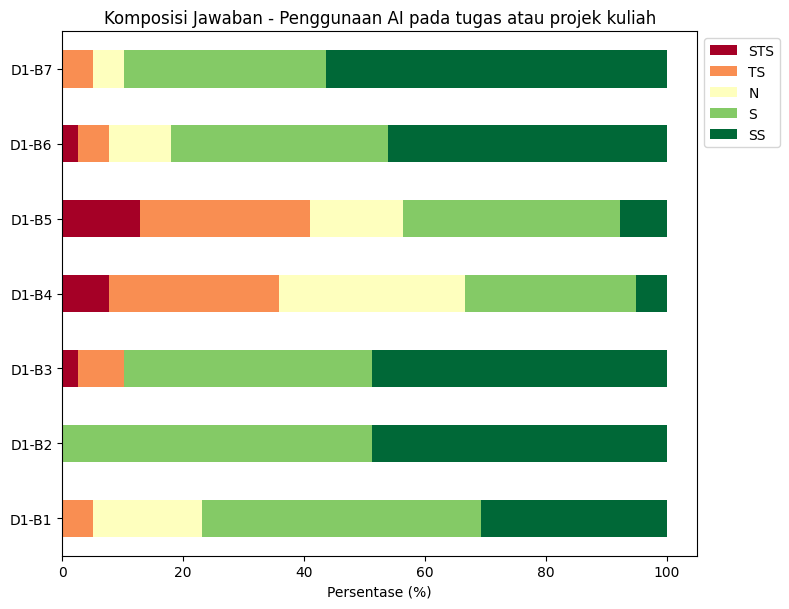

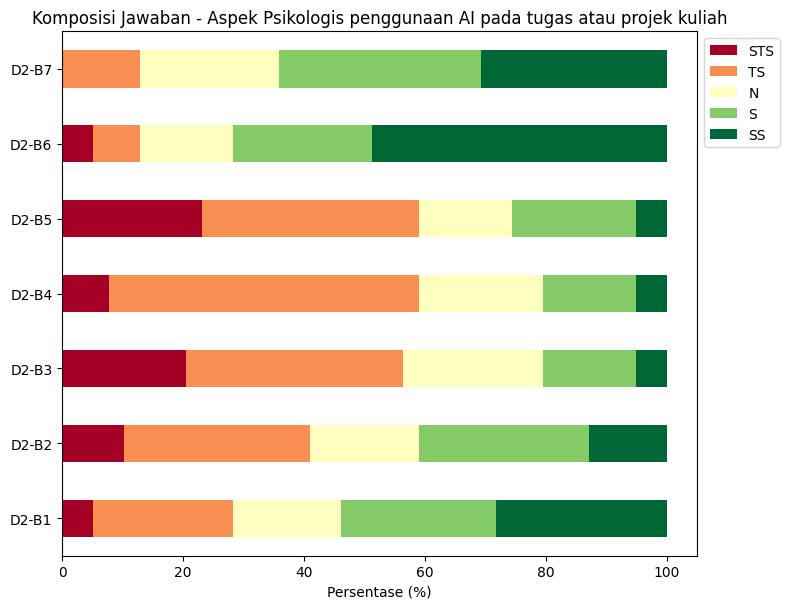

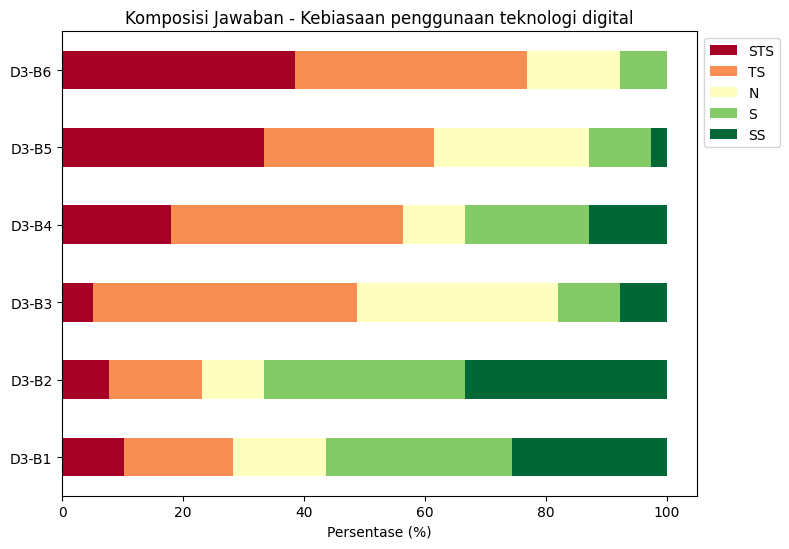

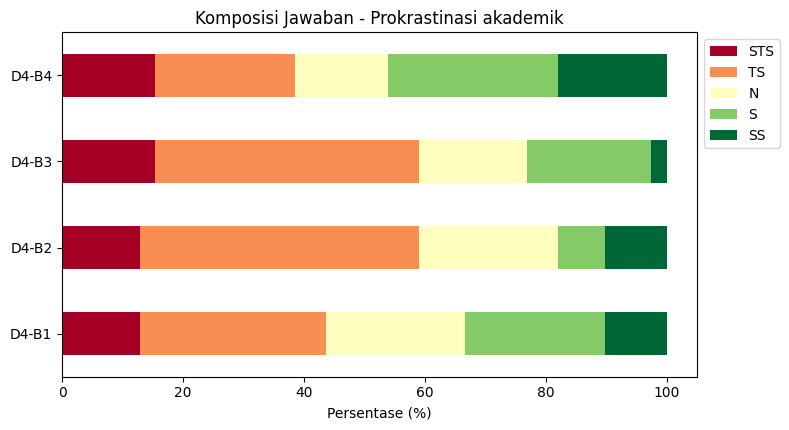

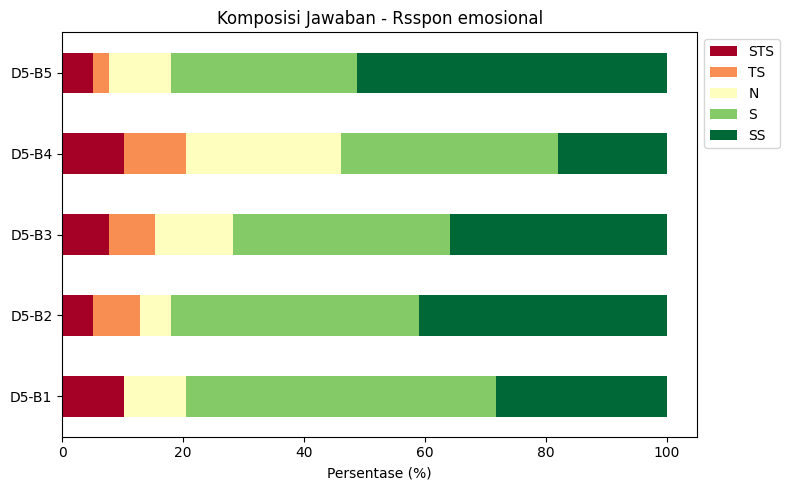

,Dimensi,Mean,Std. Deviasi,Skewness,Kurtosis
0,Penggunaan AI pada tugas atau projek kuliah,3.897,0.431,-0.425,1.612
1,Aspek Psikologis penggunaan AI pada tugas atau...,3.132,0.534,0.248,-0.752
2,Kebiasaan penggunaan teknologi digital,2.782,0.620,-0.255,-0.212
3,Prokrastinasi akademik,2.763,1.016,0.236,-0.553
4,Rsspon emosional,3.877,0.664,-1.524,3.948


In [6]:
label = {1:"STS",2:"TS",3:"N",4:"S",5:"SS"}
deskriptif = []
for d, (nama, daftar) in enumerate(dimensi.items(), 1):
    x = num[daftar]
    skor = x.mean(axis=1)                      # rata-rata skor dimensi per responden
    deskriptif.append({"Dimensi": nama, "Mean": round(skor.mean(),3),
        "Std. Deviasi": round(skor.std(ddof=1),3),
        "Skewness": round(stats.skew(skor, bias=False),3),
        "Kurtosis": round(stats.kurtosis(skor, bias=False),3)})

    # grafik komposisi jawaban (% per butir)
    komp = (x.apply(lambda s: s.value_counts(normalize=True))
              .reindex(range(1,6)).fillna(0).T * 100)
    komp.columns = [label[c] for c in komp.columns]
    komp.index = [f"D{d}-B{i}" for i in range(1, len(daftar)+1)]
    komp.plot(kind="barh", stacked=True, figsize=(8, 0.6*len(daftar)+2),
              colormap="RdYlGn")
    plt.title(f"Komposisi Jawaban - {nama}")
    plt.xlabel("Persentase (%)"); plt.legend(bbox_to_anchor=(1,1))
    plt.tight_layout()
    plt.savefig(f"grafik_D{d}.png", dpi=200); plt.show()

tabel_deskriptif = pd.DataFrame(deskriptif)
tabel_deskriptif

In [7]:
with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    tabel_kode.to_excel(w, sheet_name="Kode Butir", index=False)
    tabel_validitas.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_deskriptif.to_excel(w, sheet_name="Deskriptif", index=False)
files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>